# Step 9 — Audit the nine probability-reallocation cases
Run **Runtime → Run all**, then save to GitHub as **08_moved_probability_audit.ipynb**. Standalone: earlier setup is visible and rebuilt. No FRED request or mandatory new Kalshi API call is used.

This is a measurement audit, not another significance search. We reproduce the authors' middle-out CDF adjustment using their exported pre-adjustment prices, identify its chosen anchor, trace net probability changes and infer trade-day age from positive daily volume. We inspect all 37 included meetings, then focus on the nine whose final masses differ from stored-CDF differences.

**Limits:** exported pre-adjustment prices may already be forward-filled. Daily positive volume identifies a trading day, not an exact timestamp. A net comparison of bin masses is not an execution log of every probability swap. CDF-difference masses retain earlier repairs and endpoint assumptions.

The December 2022 API tie check is included as a small verified derived summary from a completed bounded query; no raw trade IDs or bulk trade history are embedded. Optional live verification is off by default. It shows why timestamp-only sorting cannot always define one unique last trade price.

**Sources:** [construction code](https://github.com/jdkatz21/Prediction_Markets_Public/blob/main/code/convert_trades_to_pdfs/convert_trade_level_data_cdfs.R), [published distributions](https://kalshi-and-the-rise-of-macro-markets.s3.amazonaws.com/daily_distribution_data/daily_distributions_fed_levels.csv), [historical trades API](https://docs.kalshi.com/api-reference/historical/get-historical-trades).

No sample exclusions, age threshold or alternative probability repair is selected using the Treasury regression results.

## Verified initial run — October 19, 2026
All 12 code cells ran successfully, and both figures were inspected. The middle-out price adjustment was reproduced exactly for all 37 events.

For the nine reallocation-sensitive events, the selected anchor's last positive-volume day precedes the observation date by **3–152 calendar days**, with median **67 days**. For the other 28 events the median gap is **zero days**, although some anchors are older. These are daily bounds inferred from the authors' exported volume, not exact trade ages for every contract.

In December 2022, the **86-cent** price for the **0.25% threshold** becomes the anchor and propagates through newer, higher threshold-price observations. The later probability reallocation shifts approximately **13.27 percentage points** from the lowest synthetic bin to a bin near the central outcome. The underlying bounded API query also shows two trades at the same timestamp with different prices, **86 and 99 cents**, so timestamp sorting alone does not uniquely identify a last price.

These findings support a focused review of age and tie-handling conventions. They do not establish which reconstructed distribution is true, and no revised regression, sample deletion or preferred repair is chosen here.

### Setup 1

In [1]:
import io
import json
import time
import hashlib
import urllib.request
import urllib.error
from pathlib import Path
import numpy as np
import pandas as pd

# Fixed scope. Refreshing the files can update history; hashes identify each download.
STUDY_START = pd.Timestamp("2022-01-01")
AS_OF_DATE = pd.Timestamp.now(tz="America/New_York").tz_localize(None).normalize()
SOURCES = {
  "moments": "https://kalshi-and-the-rise-of-macro-markets.s3.amazonaws.com/daily_moments_data/daily_moments_fed_levels.csv",
  "distributions": "https://kalshi-and-the-rise-of-macro-markets.s3.amazonaws.com/daily_distribution_data/daily_distributions_fed_levels.csv",
  "usmpd": "https://www.frbsf.org/wp-content/uploads/USMPD.xlsx"
}
source_receipts = []
source_bytes = {}

def download(name, url):
    for attempt in range(3):
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "ResearchProject/1.0"})
            with urllib.request.urlopen(request, timeout=45) as response:
                data = response.read()
                modified = response.headers.get("Last-Modified")
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)
    source_bytes[name] = data
    source_receipts.append({
        "source": name, "url": url, "bytes": len(data),
        "sha256": hashlib.sha256(data).hexdigest(),
        "retrieved_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "last_modified_http": modified
    })
    return data

moments = pd.read_csv(io.BytesIO(download("moments", SOURCES["moments"])))
distributions = pd.read_csv(io.BytesIO(download("distributions", SOURCES["distributions"])))
workbook = pd.ExcelFile(io.BytesIO(download("usmpd", SOURCES["usmpd"])))
statements = pd.read_excel(workbook, sheet_name="Statements")
print("Downloaded published moments, distributions and USMPD.")
print("No account credentials or API keys are needed.")


Downloaded published moments, distributions and USMPD.
No account credentials or API keys are needed.


### Setup 2

In [2]:
required_m = {"date", "contract_preamble", "mean", "variance", "daily_volume"}
required_d = {"date", "contract_preamble", "strike", "probability"}
assert required_m <= set(moments.columns), "Moments schema changed"
assert required_d <= set(distributions.columns), "Distribution schema changed"
assert {"Date", "Unscheduled", "UST2Y"} <= set(statements.columns), "USMPD schema changed"

for frame in [moments, distributions]:
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")
    assert frame["date"].notna().all()
    frame["event_key"] = frame["contract_preamble"].str.replace(r"^KX", "", regex=True)
assert not moments.duplicated(["event_key", "date"]).any(), "Duplicate event/date moments"
assert not distributions.duplicated(["event_key", "date", "strike"]).any(), "Duplicate bins"
for column in ["mean", "variance", "daily_volume"]:
    moments[column] = pd.to_numeric(moments[column], errors="raise")
for column in ["strike", "probability"]:
    distributions[column] = pd.to_numeric(distributions[column], errors="raise")
assert moments["variance"].dropna().ge(-1e-12).all(), "Negative variance"
assert distributions["probability"].dropna().between(0, 100 + 1e-8).all()

statements["Date"] = pd.to_datetime(statements["Date"], errors="raise")
assert statements["Date"].is_unique
assert statements["Unscheduled"].isin([0, 1]).all()
statements["UST2Y"] = pd.to_numeric(statements["UST2Y"], errors="raise")
# Never use the source's expiry_date as an official meeting date:
# the authors calculate it from the last observed trade day.
events = statements.loc[
    statements["Unscheduled"].eq(0) &
    statements["Date"].ge(STUDY_START) &
    statements["Date"].le(AS_OF_DATE), ["Date", "UST2Y"]
].rename(columns={"Date": "meeting_date", "UST2Y": "ust2y_change_pp"}).copy()
events["event_key"] = events["meeting_date"].map(
    lambda d: "FED-" + d.strftime("%y%b").upper()
)
assert events["event_key"].is_unique, "Two meetings share an event month; inspect mapping"
events["observation_date"] = events["meeting_date"] - pd.offsets.BDay(1)
assert events["observation_date"].lt(events["meeting_date"]).all()
print("Kalshi observation range:", moments["date"].min().date(), "to", moments["date"].max().date())
print("Latest USMPD statement:", statements["Date"].max().date())
print("Scheduled meetings in scope:", len(events))
print("Event mapping uses official USMPD meeting dates and month identifiers.")
print("Previous weekday convention: selected FOMC cutoffs must also be checked for holidays.")


Kalshi observation range: 2021-07-02 to 2026-10-16
Latest USMPD statement: 2026-09-16
Scheduled meetings in scope: 38
Event mapping uses official USMPD meeting dates and month identifiers.
Previous weekday convention: selected FOMC cutoffs must also be checked for holidays.


### Setup 3

In [3]:
# Join exactly one published daily observation to each scheduled event.
audit = events.merge(
    moments[["event_key", "date", "mean", "variance", "daily_volume"]],
    left_on=["event_key", "observation_date"],
    right_on=["event_key", "date"], how="left", validate="one_to_one",
    indicator="moments_match"
)
assert len(audit) == len(events)
targets = events[["event_key", "observation_date"]]
bins = distributions.merge(
    targets, left_on=["event_key", "date"],
    right_on=["event_key", "observation_date"],
    how="inner", validate="many_to_one"
)
checks = []
for (event_key, date), group in bins.groupby(["event_key", "date"]):
    p = group["probability"].to_numpy(dtype=float) / 100
    x = group["strike"].to_numpy(dtype=float)
    finite = np.isfinite(p).all() and np.isfinite(x).all()
    total = p.sum()
    if finite and total > 0:
        weights = p / total
        mean_unadjusted = np.sum(weights * x)
        var_rebuilt = np.sum(weights * (x - mean_unadjusted) ** 2)
    else:
        mean_unadjusted = var_rebuilt = np.nan
    checks.append({
        "event_key": event_key, "observation_date": date,
        "probability_sum": total, "bins": len(group),
        "rebuilt_variance_pp2": var_rebuilt,
        "rebuilt_mean_pp": mean_unadjusted + 0.125,
        "distribution_valid": bool(finite and np.isclose(total, 1, atol=1e-8))
    })
checks = pd.DataFrame(checks, columns=[
    "event_key", "observation_date", "probability_sum", "bins",
    "rebuilt_variance_pp2", "rebuilt_mean_pp", "distribution_valid"
])
audit = audit.merge(checks, on=["event_key", "observation_date"],
                    how="left", validate="one_to_one")
audit["variance_matches"] = np.isclose(
    audit["variance"], audit["rebuilt_variance_pp2"], atol=1e-10, rtol=1e-7
)
audit["mean_matches"] = np.isclose(
    audit["mean"], audit["rebuilt_mean_pp"], atol=1e-8, rtol=1e-7
)
audit["ust2y_signed_bps"] = audit["ust2y_change_pp"] * 100
audit["abs_ust2y_bps"] = audit["ust2y_signed_bps"].abs()
audit["kalshi_sigma_bps"] = np.sqrt(audit["variance"].clip(lower=0)) * 100

def inclusion_reason(row):
    if row["moments_match"] != "both":
        return "exclude: missing exact previous-day moments"
    if not np.isfinite(row["ust2y_signed_bps"]):
        return "exclude: missing Treasury outcome"
    if not np.isfinite(row["variance"]) or row["variance"] < -1e-12:
        return "exclude: invalid variance"
    if not (pd.notna(row["distribution_valid"]) and row["distribution_valid"]):
        return "exclude: missing or invalid distribution"
    if not row["variance_matches"] or not row["mean_matches"]:
        return "exclude: published moments do not reconcile"
    return "include: published-method candidate"

audit["inclusion_reason"] = audit.apply(inclusion_reason, axis=1)
audit["included"] = audit["inclusion_reason"].eq("include: published-method candidate")
print(audit[["meeting_date", "observation_date", "kalshi_sigma_bps",
             "abs_ust2y_bps", "inclusion_reason"]].round(3).to_string(index=False))
print("\nYear-level coverage:")
print(audit.groupby(audit["meeting_date"].dt.year).agg(
    scheduled=("included", "size"), included=("included", "sum")
).to_string())


meeting_date observation_date  kalshi_sigma_bps  abs_ust2y_bps                            inclusion_reason
  2022-01-26       2022-01-25             4.307          0.190         include: published-method candidate
  2022-03-16       2022-03-15             7.468         10.900         include: published-method candidate
  2022-05-04       2022-05-03             7.970          4.700         include: published-method candidate
  2022-06-15       2022-06-14            13.216          5.050         include: published-method candidate
  2022-07-27       2022-07-26             8.183          0.200         include: published-method candidate
  2022-09-21       2022-09-20             6.559          9.390         include: published-method candidate
  2022-11-02       2022-11-01             5.595          8.720         include: published-method candidate
  2022-12-14       2022-12-13             8.480          8.580         include: published-method candidate
  2023-02-01       2023-01-31        

### Setup 4

In [4]:
dataset = audit.loc[audit["included"], [
    "meeting_date", "event_key", "observation_date", "mean",
    "kalshi_sigma_bps", "ust2y_signed_bps", "abs_ust2y_bps",
    "daily_volume", "probability_sum", "bins"
]].rename(columns={
    "mean": "authors_adjusted_mean_rate_pct",
    "daily_volume": "authors_daily_volume"
}).sort_values("meeting_date").reset_index(drop=True)

assert dataset["meeting_date"].is_unique
assert dataset["observation_date"].lt(dataset["meeting_date"]).all()
assert np.isfinite(dataset[["kalshi_sigma_bps", "abs_ust2y_bps"]]).all().all()
assert dataset["kalshi_sigma_bps"].ge(0).all()
print("Reconciled candidate events:", len(dataset))
print("Excluded scheduled events:", int((~audit["included"]).sum()))
print("Zero constructed uncertainty:", int(dataset["kalshi_sigma_bps"].eq(0).sum()))
print("\nDescriptive ranges (basis points):")
print(dataset[["kalshi_sigma_bps", "abs_ust2y_bps"]].describe().round(3).to_string())
print("\nLIMITS:")
print("- This is a dataset using the authors' processed measures, not an exact raw distribution.")
print("- Daily prices can be carried forward; daily volume does not establish age of every strike.")
print("- UTC calendar-day aggregation replaces the original 16:00 Eastern cutoff.")
print("- Reconciled means include the authors' 0.125 percentage-point adjustment.")
print("- Constructed zero variance does not establish zero true uncertainty.")
print("- Corrections, tail conventions and retrospective processing require sensitivity checks.")
print("- No claims of predictive skill or causality are made; no regressions have been run.")
print("- Policy surprise, revision volatility and conventional benchmark are not yet built.")


Reconciled candidate events: 37
Excluded scheduled events: 1
Zero constructed uncertainty: 5

Descriptive ranges (basis points):
       kalshi_sigma_bps  abs_ust2y_bps
count            37.000         37.000
mean              5.088          4.010
std               3.533          3.468
min               0.000          0.000
25%               2.512          1.040
50%               4.307          2.770
75%               7.892          6.525
max              13.216         11.775

LIMITS:
- This is a dataset using the authors' processed measures, not an exact raw distribution.
- Daily prices can be carried forward; daily volume does not establish age of every strike.
- UTC calendar-day aggregation replaces the original 16:00 Eastern cutoff.
- Reconciled means include the authors' 0.125 percentage-point adjustment.
- Constructed zero variance does not establish zero true uncertainty.
- Corrections, tail conventions and retrospective processing require sensitivity checks.
- No claims of predi

### Setup 5

In [5]:
MPU_URL = "https://www.frbsf.org/wp-content/uploads/market-based-monetary-policy-uncertainty-data.xlsx"
mpu_bytes = download("mpu", MPU_URL)
mpu_book = pd.ExcelFile(io.BytesIO(mpu_bytes))
assert {"readme", "mpu"} <= set(mpu_book.sheet_names)
mpu = pd.read_excel(mpu_book, sheet_name="mpu")
assert {"Date", "6 months"} <= set(mpu.columns), "Benchmark schema changed"
mpu["Date"] = pd.to_datetime(mpu["Date"], errors="raise")
mpu["6 months"] = pd.to_numeric(mpu["6 months"], errors="raise")
assert mpu["Date"].is_unique and mpu["Date"].notna().all()
assert mpu["6 months"].dropna().ge(0).all()

# The source is already a standard deviation, in percentage points.
# Multiply by 100 for bps; do NOT take another square root.
mpu["mpu6m_bps"] = mpu["6 months"] * 100
enriched = dataset.merge(
    mpu[["Date", "mpu6m_bps"]].rename(columns={"Date": "mpu_observation_date"}),
    left_on="observation_date", right_on="mpu_observation_date",
    how="left", validate="one_to_one"
)
assert len(enriched) == len(dataset)
assert enriched["mpu_observation_date"].dropna().lt(
    enriched.loc[enriched["mpu_observation_date"].notna(), "meeting_date"]
).all()
print("Latest benchmark observation:", mpu["Date"].max().date())
print("Exact previous-day benchmark matches:", enriched["mpu6m_bps"].notna().sum(),
      "of", len(enriched))
print("No backward-as-of substitution or interpolation applied.")
print("Benchmark covers six-month policy-path uncertainty, not immediate-decision uncertainty.")
print("Underlying derivatives switch from Eurodollar to SOFR in October 2022.")


Latest benchmark observation: 2026-10-09
Exact previous-day benchmark matches: 37 of 37
No backward-as-of substitution or interpolation applied.
Benchmark covers six-month policy-path uncertainty, not immediate-decision uncertainty.
Underlying derivatives switch from Eurodollar to SOFR in October 2022.


### Setup 6

In [6]:
from pandas.tseries.holiday import USFederalHolidayCalendar
from dateutil.easter import easter

# Five daily revisions need SIX level observations for the SAME meeting.
# In this sample, check that the selected weekdays contain no federal
# holidays or Good Friday. A future flagged window needs calendar review.
years = range(int(enriched["meeting_date"].dt.year.min()) - 1,
              int(enriched["meeting_date"].dt.year.max()) + 1)
closed_dates = USFederalHolidayCalendar().holidays(
    start=f"{min(years)}-01-01", end=f"{max(years)}-12-31"
).union(pd.DatetimeIndex([
    pd.Timestamp(easter(year)) - pd.Timedelta(days=2) for year in years
]))
revision_rows = []
window_rows = []
indexed = moments.set_index(["event_key", "date"]).sort_index()
for _, event in enriched.iterrows():
    dates = pd.bdate_range(end=event["observation_date"], periods=6)
    holiday_flag = bool(dates.isin(closed_dates).any())
    key = pd.MultiIndex.from_product(
        [[event["event_key"]], dates], names=["event_key", "date"]
    )
    window = indexed.reindex(key)
    mean_levels = window["mean"].to_numpy(dtype=float) * 100
    complete = bool(np.isfinite(mean_levels).all()) and not holiday_flag
    changes = np.diff(mean_levels) if complete else np.full(5, np.nan)
    rv5 = float(np.sqrt(np.sum(changes ** 2))) if complete else np.nan
    mean_abs = float(np.mean(np.abs(changes))) if complete else np.nan
    zero_volume_days = int(window["daily_volume"].eq(0).sum())
    revision_rows.append({
        "meeting_date": event["meeting_date"],
        "rv5_bps": rv5,
        "mean_abs_daily_revision_bps": mean_abs,
        "revision_level_observations": int(np.isfinite(mean_levels).sum()),
        "revision_window_complete": complete,
        "revision_calendar_review": holiday_flag,
        "window_zero_volume_days": zero_volume_days
    })
    for position, date in enumerate(dates):
        window_rows.append({
            "meeting_date": event["meeting_date"], "event_key": event["event_key"],
            "observation_date": date, "authors_adjusted_mean_bps": mean_levels[position],
            "change_from_previous_bps": changes[position-1] if position else np.nan,
            "authors_daily_volume": window["daily_volume"].iloc[position],
            "window_complete": complete
        })
revision_audit = pd.DataFrame(revision_rows)
revision_windows = pd.DataFrame(window_rows)
assert revision_windows["observation_date"].lt(revision_windows["meeting_date"]).all()
assert not revision_windows.duplicated(
    ["meeting_date", "observation_date"]
).any()
enriched = enriched.merge(revision_audit, on="meeting_date",
                          how="left", validate="one_to_one")
assert len(enriched) == len(dataset)
print("Complete five-revision windows:",
      int(enriched["revision_window_complete"].sum()), "of", len(enriched))
print("Calendar-review windows:", int(enriched["revision_calendar_review"].sum()))
print("Windows with zero published daily volume:",
      int(enriched["window_zero_volume_days"].gt(0).sum()))
print("Missing levels remain missing; no partial-window RV or zero filling.")
print("Published forward-filled levels may still conceal stale underlying strikes.")


Complete five-revision windows: 37 of 37
Calendar-review windows: 0
Windows with zero published daily volume: 6
Missing levels remain missing; no partial-window RV or zero filling.
Published forward-filled levels may still conceal stale underlying strikes.


### Setup 7

In [7]:
# Fix the specifications before inspecting regressions.
# A: absolute yield move ~ decision sigma
# B0/B1: baseline alone versus baseline + decision sigma, on IDENTICAL rows
# P0/P1: baseline alone versus baseline + revision RV, estimated in parallel
# Do not put sigma, RV and many additional controls into a kitchen-sink model.
enriched["sample_A"] = np.isfinite(
    enriched[["abs_ust2y_bps", "kalshi_sigma_bps"]]
).all(axis=1)
enriched["sample_B"] = enriched["sample_A"] & np.isfinite(enriched["mpu6m_bps"])
enriched["sample_revision"] = (
    np.isfinite(enriched[["abs_ust2y_bps", "mpu6m_bps", "rv5_bps"]]).all(axis=1)
    & enriched["revision_window_complete"]
)
print(enriched[[
    "meeting_date", "kalshi_sigma_bps", "mpu6m_bps", "rv5_bps",
    "revision_level_observations", "sample_B", "sample_revision"
]].round(3).to_string(index=False))
print("\nFrozen candidate sample sizes:")
print("A, sigma only:", int(enriched["sample_A"].sum()))
print("B, baseline versus baseline + sigma:", int(enriched["sample_B"].sum()))
print("Parallel baseline versus baseline + RV:", int(enriched["sample_revision"].sum()))
print("\nPre-specified sensitivity checks:")
print("- Spearman correlation, HC3 inference and leave-one-event-out sensitivity")
print("- Zero-constructed-sigma exclusions as sensitivity only, not significance-based selection")
print("- Alternate statement/full-event windows and reasonable measurement conventions")
print("- Eurodollar/SOFR source transition is documented; avoid overfitting regime splits")
print("No regressions or significance searches have been run.")
print("Policy-surprise analysis remains separate; no realized surprise is an ex-ante predictor.")

OUTPUT = Path("research_outputs")
OUTPUT.mkdir(exist_ok=True)
enriched.to_csv(OUTPUT / "meeting_dataset_with_predictors.csv", index=False)
revision_windows.to_csv(OUTPUT / "revision_window_audit.csv", index=False)
revision_audit.to_csv(OUTPUT / "revision_completeness_audit.csv", index=False)
metadata = {
    "sources": source_receipts,
    "baseline": "Previous-day SF Fed 6-month market-based uncertainty; native pp * 100 = bps",
    "revision": "sqrt(sum of five squared revisions across six pre-announcement daily means)); means * 100 = bps",
    "timing": "Previous UTC day; weekday windows checked against federal holidays and Good Friday",
    "missingness": "Exact-date joins only; no additional forward filling; incomplete revision windows excluded only from revision models",
    "method_limits": [
        "Authors' daily Kalshi levels already carry forward stale prices and apply distribution repairs",
        "Daily aggregate volume does not identify exact age of every underlying strike",
        "Historical files are current-vintage processed data, not a verified real-time vintage archive",
        "Different market horizons and daily closing times limit direct comparability"
    ],
    "candidate_model_samples": {
        "A": int(enriched["sample_A"].sum()), "B": int(enriched["sample_B"].sum()),
        "revision_parallel": int(enriched["sample_revision"].sum())
    }
}
(OUTPUT / "predictor_provenance.json").write_text(json.dumps(metadata, indent=2))
print("\nSaved derived dataset, two revision audits and provenance under research_outputs/.")
print("Raw source files are not exported.")
print("Save to ResearchProject / main as 05_predictors_benchmark.ipynb.")


meeting_date  kalshi_sigma_bps  mpu6m_bps  rv5_bps  revision_level_observations  sample_B  sample_revision
  2022-01-26             4.307     41.713    1.052                            6      True             True
  2022-03-16             7.468     83.628    1.593                            6      True             True
  2022-05-04             7.970    102.297    3.287                            6      True             True
  2022-06-15            13.216    123.957   15.622                            6      True             True
  2022-07-27             8.183    108.859    0.920                            6      True             True
  2022-09-21             6.559     92.942    2.134                            6      True             True
  2022-11-02             5.595     90.428    1.112                            6      True             True
  2022-12-14             8.480     72.310    3.894                            6      True             True
  2023-02-01             3.571     53

### Setup 8

In [8]:
import sys
import importlib.util
import subprocess
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])
import statsmodels
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BOOTSTRAP_REPS = 4999
RANDOM_SEED = 20261019
FIGURES = Path("research_outputs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#242424", "text.color": "#242424",
    "figure.facecolor": "white", "axes.facecolor": "white"
})
BLUE, ORANGE, GREY = "#245B83", "#AF6427", "#666666"
print("Versions:", {"pandas": pd.__version__, "numpy": np.__version__,
                    "statsmodels": statsmodels.__version__})
print("Analysis scope fixed before fitting: A sigma; B baseline + sigma; parallel baseline + RV.")
print("Outcome: absolute statement-window two-year yield change in bps.")


Versions: {'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0'}
Analysis scope fixed before fitting: A sigma; B baseline + sigma; parallel baseline + RV.
Outcome: absolute statement-window two-year yield change in bps.


### 1. Reproduce the adjustment and identify anchor trade-day ages
The code reproduces the source algorithm, then checks agreement with the stored adjusted prices. Probability reallocation is identified without using Treasury reaction sizes.

In [9]:
def middle_out_from_export(group):
    # Match the authors' source code: first threshold closest to 49 cents,
    # then cumulative max to its left and cumulative min to its right.
    observed = group.loc[
        pd.to_numeric(group["yes_price"], errors="raise").gt(0)
    ].sort_values("strike").copy()
    prices = observed["yes_price"].to_numpy(dtype=float)
    k = int(np.argmin(np.abs(prices - 49)))
    adjusted = prices.copy()
    adjusted[:k+1] = np.maximum.accumulate(prices[:k+1][::-1])[::-1]
    adjusted[k:] = np.minimum.accumulate(prices[k:])
    return observed, k, adjusted

def activity_day(history, strike, cutoff):
    series = history.loc[
        history["strike"].eq(strike) & history["date"].le(cutoff)
    ].sort_values("date")
    trades = series.loc[series["daily_volume"].gt(0)]
    if trades.empty:
        return pd.NaT, np.nan
    last = trades["date"].max()
    return last, float((cutoff - last).days)

anchor_rows, bin_rows, threshold_rows = [], [], []
event_groups = {}
for _, event in enriched.iterrows():
    history = distributions.loc[
        distributions["event_key"].eq(event["event_key"]) &
        distributions["date"].le(event["observation_date"])
    ].copy()
    group = history.loc[history["date"].eq(event["observation_date"])].sort_values("strike").copy()
    for column in ["yes_price", "adjusted_yes_price", "daily_volume"]:
        group[column] = pd.to_numeric(group[column], errors="raise")
        history[column] = pd.to_numeric(history[column], errors="raise")
    observed, k, rebuilt = middle_out_from_export(group)
    assert np.allclose(rebuilt, observed["adjusted_yes_price"], atol=1e-8), (
        f"Source algorithm no longer matches stored CDF: {event['event_key']}"
    )
    anchor = observed.iloc[k]
    last_day, age_gap = activity_day(history, anchor["strike"], event["observation_date"])
    q = group["adjusted_yes_price"].to_numpy(dtype=float)
    weights = group["probability"].to_numpy(dtype=float) / 100
    weights /= weights.sum()
    difference = np.empty(len(group))
    difference[0] = 99 - q[1]
    difference[1:-1] = q[1:-1] - q[2:]
    difference[-1] = q[-1] - 1
    assert (difference >= -1e-8).all()
    difference = np.maximum(difference, 0)
    difference /= difference.sum()
    x = group["strike"].to_numpy(dtype=float)
    mu = np.sum(difference * x)
    alternative_sigma = np.sqrt(np.sum(difference * (x-mu)**2)) * 100
    tv = float(np.sum(np.abs(difference - weights)) / 2)
    affected = tv > 1e-10
    if not affected:
        assert np.isclose(alternative_sigma, event["kalshi_sigma_bps"], atol=1e-8)
    anchor_rows.append({
        "meeting_date": event["meeting_date"], "event_key": event["event_key"],
        "observation_date": event["observation_date"],
        "probability_reallocation_affected": affected,
        "anchor_threshold_pct": anchor["strike"],
        "anchor_exported_price_cents": anchor["yes_price"],
        "anchor_last_positive_volume_day": last_day,
        "anchor_trade_day_gap": age_gap,
        "anchor_trade_age_upper_days": age_gap + 1 if np.isfinite(age_gap) else np.nan,
        "anchor_cutoff_day_volume": anchor["daily_volume"],
        "max_CDF_reproduction_error_cents": float(np.max(np.abs(
            rebuilt - observed["adjusted_yes_price"].to_numpy()))),
        "authors_sigma_bps": event["kalshi_sigma_bps"],
        "stored_CDF_sigma_bps": alternative_sigma,
        "relocated_probability_percentage_points": tv * 100
    })
    event_groups[event["event_key"]] = {
        "meeting_date": event["meeting_date"], "group": group,
        "cdf_weights": difference, "published_weights": weights
    }
    if affected:
        for j, (_, row) in enumerate(group.iterrows()):
            day, gap = activity_day(history, row["strike"], event["observation_date"])
            next_day, next_gap = (
                activity_day(history, group.iloc[j+1]["strike"], event["observation_date"])
                if j + 1 < len(group) else (pd.NaT, np.nan)
            )
            delta = (weights[j] - difference[j]) * 100
            bin_rows.append({
                "meeting_date": event["meeting_date"], "event_key": event["event_key"],
                "observation_date": event["observation_date"],
                "bin_anchor_pct": row["strike"],
                "bin_midpoint_convention_pct": row["strike"] + 0.125,
                "CDF_difference_probability_pct": difference[j] * 100,
                "published_probability_pct": weights[j] * 100,
                "net_probability_change_pp": delta,
                "boundary_last_positive_volume_day": day,
                "boundary_trade_day_gap": gap,
                "next_boundary_last_positive_volume_day": next_day,
                "next_boundary_trade_day_gap": next_gap
            })
        for _, row in observed.iterrows():
            day, gap = activity_day(history, row["strike"], event["observation_date"])
            threshold_rows.append({
                "meeting_date": event["meeting_date"], "threshold_pct": row["strike"],
                "exported_last_price_cents": row["yes_price"],
                "stored_adjusted_price_cents": row["adjusted_yes_price"],
                "price_adjustment_cents": row["adjusted_yes_price"] - row["yes_price"],
                "last_positive_volume_day": day, "trade_day_gap": gap,
                "cutoff_day_volume": row["daily_volume"],
                "is_selected_anchor": bool(row["strike"] == anchor["strike"])
            })
anchor_audit = pd.DataFrame(anchor_rows)
bin_audit = pd.DataFrame(bin_rows)
threshold_audit = pd.DataFrame(threshold_rows)
assert len(anchor_audit) == len(enriched)
assert anchor_audit["meeting_date"].is_unique
assert np.allclose(bin_audit.groupby("meeting_date")["net_probability_change_pp"].sum(), 0, atol=1e-8)
affected_events = anchor_audit.loc[anchor_audit["probability_reallocation_affected"]].copy()
print("Middle-out adjustment exactly reproduced for", len(anchor_audit), "meetings.")
print("Reallocation-sensitive meetings:", len(affected_events))
print(affected_events[[
    "meeting_date", "anchor_threshold_pct", "anchor_exported_price_cents",
    "anchor_last_positive_volume_day", "anchor_trade_day_gap",
    "authors_sigma_bps", "stored_CDF_sigma_bps", "relocated_probability_percentage_points"
]].round(3).to_string(index=False))
print("\nAnchor trade-day gaps for affected AND unaffected meetings:")
print(anchor_audit.groupby("probability_reallocation_affected")["anchor_trade_day_gap"]
      .agg(["count", "min", "median", "max"]).to_string())
print("Age is a calendar-day interval inferred from positive source volume, not an exact timestamp.")
print("At the end of the selected UTC day, a gap of 3 implies age in [3,4) days if the source history is complete.")
print("Unknown age remains missing; a constant price does not establish that no trades occurred.")


Middle-out adjustment exactly reproduced for 37 meetings.
Reallocation-sensitive meetings: 9
meeting_date  anchor_threshold_pct  anchor_exported_price_cents anchor_last_positive_volume_day  anchor_trade_day_gap  authors_sigma_bps  stored_CDF_sigma_bps  relocated_probability_percentage_points
  2022-11-02                  1.50                         95.0                      2022-06-02                 152.0              5.595                49.582                                    4.082
  2022-12-14                  0.25                         86.0                      2022-12-10                   3.0              8.480               144.160                                   13.265
  2023-07-26                  6.00                          2.0                      2023-06-01                  54.0              2.512                 7.537                                    1.020
  2024-01-31                  6.00                          3.0                      2023-10-25            

### 2. Trace changed bins and inspect December 2022
Compare where mass is lost and gained. The synthetic bottom bin depends on the lowest real threshold; its own zero price is not an observed market quote. Both boundary trade-day gaps are retained where available.

In [10]:
changed_bins = bin_audit.loc[bin_audit["net_probability_change_pp"].abs().gt(1e-8)]
print("NET BIN CHANGES: positive = more published probability; negative = less.")
print(changed_bins[[
    "meeting_date", "bin_midpoint_convention_pct", "CDF_difference_probability_pct",
    "published_probability_pct", "net_probability_change_pp",
    "boundary_trade_day_gap", "next_boundary_trade_day_gap"
]].round(3).to_string(index=False))
print("This is a net mass comparison, not a recovered log of the authors' individual swaps.")
december = threshold_audit.loc[threshold_audit["meeting_date"].eq(pd.Timestamp("2022-12-14"))]
print("\nDECEMBER 2022 THRESHOLD-PRICE AUDIT")
print(december.round(3).to_string(index=False))
print("\nSource algorithm chooses the threshold closest to a 49-cent YES price.")
print("That chosen threshold is not guaranteed to be near the expected rate or recently traded.")
print("In Dec 2022 the 0.25% threshold's 86-cent price becomes the anchor,")
print("and the monotonicity step lowers multiple newer 99-cent observations to 86 cents.")
print("The later reallocation then moves the resulting distant probability mass toward the center.")
print("Neither the unreallocated tail distribution nor the repaired distribution is independently validated by this comparison.")


NET BIN CHANGES: positive = more published probability; negative = less.
meeting_date  bin_midpoint_convention_pct  CDF_difference_probability_pct  published_probability_pct  net_probability_change_pp  boundary_trade_day_gap  next_boundary_trade_day_gap
  2022-11-02                        1.375                           4.082                      0.000                     -4.082                   110.0                        152.0
  2022-11-02                        3.625                           0.000                      4.082                      4.082                     0.0                          0.0
  2022-12-14                        0.125                          13.265                      0.000                    -13.265                     NaN                          3.0
  2022-12-14                        4.125                           0.000                     13.265                     13.265                     1.0                          0.0
  2023-07-26          

### 3. Inspect the verified tied-timestamp case
Two prices at exactly the same timestamp have no unique ordering from time alone. A same-timestamp weighted price is one possible rule; this notebook does not adopt it as truth or rerun the financial model to favor a result.

In [11]:
# Small DERIVED API audit summary verified on 2026-10-19.
# No raw trade IDs or bulk trade history are embedded or exported.
tie_check = {
    "ticker": "FED-22DEC-T0.25",
    "query_start_utc": "2022-12-01T00:00:00Z",
    "query_end_utc": "2022-12-13T23:59:59Z",
    "complete_bounded_query": True,
    "trades_in_bounded_query": 2,
    "latest_timestamp_utc": "2022-12-10T14:51:19.166081Z",
    "trades_at_latest_timestamp": 2,
    "distinct_yes_prices_dollars": [0.86, 0.99],
    "aggregate_contracts_at_timestamp": 2194.0,
    "volume_weighted_yes_price_at_timestamp": 0.9785050136736555,
    "parsed_response_snapshot_sha256": "ecb8e58d45f017f45ff9b71b4e191e5b8aaf8edfb5ac050c6a8a253385024060",
    "source_endpoint": "https://external-api.kalshi.com/trade-api/v2/historical/trades",
    "verified_on_utc_date": "2026-10-19"
}
assert tie_check["complete_bounded_query"]
assert tie_check["trades_at_latest_timestamp"] == 2
assert len(tie_check["distinct_yes_prices_dollars"]) == 2
cutoff_end = pd.Timestamp("2022-12-14", tz="UTC")
tie_check["hours_from_latest_timestamp_to_daily_cutoff"] = (
    cutoff_end - pd.Timestamp(tie_check["latest_timestamp_utc"])
).total_seconds() / 3600
print(json.dumps(tie_check, indent=2))
print("\nThe 86-cent and 99-cent observations have the SAME timestamp.")
print("Time ordering alone cannot determine a unique last price in this batch.")
print("The authors' export selects 86 cents; another within-timestamp ordering can select 99.")
print("A volume-weighted same-timestamp price would be about 97.85 cents.")
print("That is a candidate tie convention, not proof of the true market probability.")
print("The R code sorts by created_time and then uses last(yes_price); no economic tie rule is specified.")

# Optional, bounded recheck. OFF by default so the verified audit has no new API dependency.
RUN_LIVE_TIE_RECHECK = False
if RUN_LIVE_TIE_RECHECK:
    import urllib.parse
    query = urllib.parse.urlencode({
        "ticker": tie_check["ticker"], "min_ts": int(pd.Timestamp(tie_check["query_start_utc"]).timestamp()),
        "max_ts": int(pd.Timestamp(tie_check["query_end_utc"]).timestamp()), "limit": 1000
    })
    live = json.loads(download("dec22_anchor_trade_recheck", tie_check["source_endpoint"] + "?" + query))
    if live.get("cursor"):
        print("Live check is incomplete; no latest-trade conclusion drawn from this bounded page.")
    else:
        trades = live.get("trades", [])
        times = [pd.Timestamp(t["created_time"]) for t in trades]
        assert times and max(times) < cutoff_end
        latest = max(times)
        batch = [t for t in trades if pd.Timestamp(t["created_time"]) == latest]
        print("Live latest timestamp:", latest)
        print("Live distinct prices:", sorted(set(float(t["yes_price_dollars"]) for t in batch)))
        print("Live batch size:", len(batch))


{
  "ticker": "FED-22DEC-T0.25",
  "query_start_utc": "2022-12-01T00:00:00Z",
  "query_end_utc": "2022-12-13T23:59:59Z",
  "complete_bounded_query": true,
  "trades_in_bounded_query": 2,
  "latest_timestamp_utc": "2022-12-10T14:51:19.166081Z",
  "trades_at_latest_timestamp": 2,
  "distinct_yes_prices_dollars": [
    0.86,
    0.99
  ],
  "aggregate_contracts_at_timestamp": 2194.0,
  "volume_weighted_yes_price_at_timestamp": 0.9785050136736555,
  "parsed_response_snapshot_sha256": "ecb8e58d45f017f45ff9b71b4e191e5b8aaf8edfb5ac050c6a8a253385024060",
  "source_endpoint": "https://external-api.kalshi.com/trade-api/v2/historical/trades",
  "verified_on_utc_date": "2026-10-19",
  "hours_from_latest_timestamp_to_daily_cutoff": 81.1446760886111
}

The 86-cent and 99-cent observations have the SAME timestamp.
Time ordering alone cannot determine a unique last price in this batch.
The authors' export selects 86 cents; another within-timestamp ordering can select 99.
A volume-weighted same-timesta

### 4. Visualize the mechanism and save the audit
The first figure traces prices and resulting bin masses for December 2022. The second shows the selected anchors' daily age bounds across the nine affected meetings. The remaining measurement questions are preserved in the manifest.

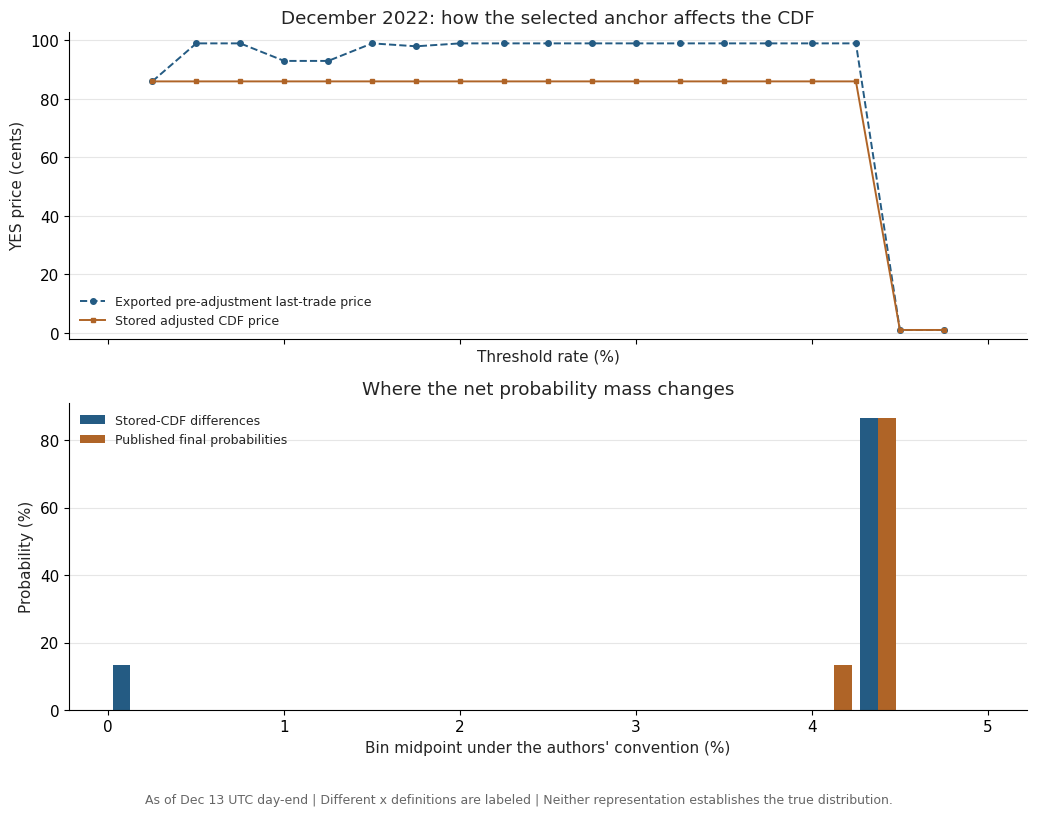

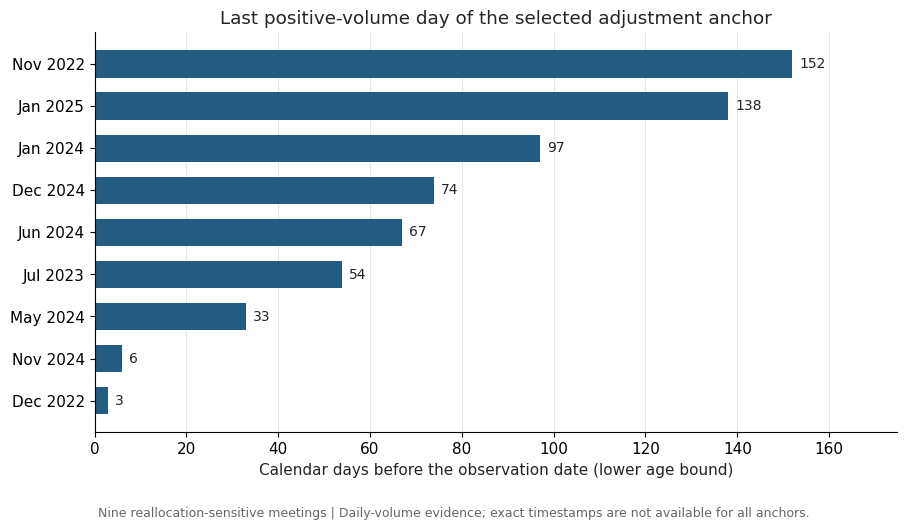

Saved three derived audit tables, tie-check summary, manifest and two figures.
No regressions were added and no original observations were deleted.
Main result remains provisional because it depends on these processing choices.
Save to ResearchProject / main as 08_moved_probability_audit.ipynb.


In [12]:
event = event_groups["FED-22DEC"]
group = event["group"].sort_values("strike")
observed = group.loc[group["yes_price"].gt(0)]
fig, axes = plt.subplots(2, 1, figsize=(10.5, 8.2), sharex=True)
axes[0].plot(observed["strike"], observed["yes_price"], "o--", color=BLUE,
             linewidth=1.4, markersize=4, label="Exported pre-adjustment last-trade price")
axes[0].plot(observed["strike"], observed["adjusted_yes_price"], "s-", color=ORANGE,
             linewidth=1.4, markersize=3.5, label="Stored adjusted CDF price")
axes[0].set(title="December 2022: how the selected anchor affects the CDF",
            ylabel="YES price (cents)", ylim=(-2, 103))
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
centers = group["strike"].to_numpy() + 0.125
width = 0.10
axes[1].bar(centers-width/2, event["cdf_weights"]*100, width=width,
            color=BLUE, label="Stored-CDF differences")
axes[1].bar(centers+width/2, event["published_weights"]*100, width=width,
            color=ORANGE, label="Published final probabilities")
axes[1].set(title="Where the net probability mass changes",
            xlabel="Threshold / bin-midpoint convention (%) — see panel definitions",
            ylabel="Probability (%)")
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
# Top panel uses threshold x; bottom uses the authors' bin midpoint convention.
axes[0].set_xlabel("Threshold rate (%)")
axes[1].set_xlabel("Bin midpoint under the authors' convention (%)")
for ax in axes:
    ax.grid(axis="y", color="#E6E6E6")
    ax.set_axisbelow(True)
fig.text(0.5, 0.012, "As of Dec 13 UTC day-end | Different x definitions are labeled | Neither representation establishes the true distribution.",
         ha="center", fontsize=9, color=GREY)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURES / "06_dec2022_probability_audit.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9.2, 5.3))
ordered = affected_events.sort_values("anchor_trade_day_gap")
labels = ordered["meeting_date"].dt.strftime("%b %Y")
ax.barh(labels, ordered["anchor_trade_day_gap"], color=BLUE, height=0.65)
for position, value in enumerate(ordered["anchor_trade_day_gap"]):
    ax.text(value+1.5, position, f"{value:.0f}", va="center", fontsize=10)
ax.set(title="Last positive-volume day of the selected adjustment anchor",
       xlabel="Calendar days before the observation date (lower age bound)")
ax.set_xlim(0, ordered["anchor_trade_day_gap"].max()*1.15)
ax.grid(axis="x", color="#E6E6E6")
ax.set_axisbelow(True)
fig.text(0.5, 0.012, "Nine reallocation-sensitive meetings | Daily-volume evidence; exact timestamps are not available for all anchors.",
         ha="center", fontsize=9, color=GREY)
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(FIGURES / "07_anchor_trade_day_gaps.png", dpi=160)
plt.show()
for name, frame in {
    "all_meeting_anchor_audit": anchor_audit,
    "affected_bin_changes": bin_audit,
    "affected_threshold_adjustments": threshold_audit
}.items():
    frame.to_csv(OUTPUT / f"audit_{name}.csv", index=False)
(OUTPUT / "audit_dec22_trade_tie_summary.json").write_text(json.dumps(tie_check, indent=2))
manifest = {
    "source_receipts": source_receipts,
    "construction_code_blob_sha": "4b84c2fe160683499dea20a1f5b36d5b3679b586",
    "observed_algorithm": "First threshold closest to 49 cents, followed by middle-out monotonicity enforcement",
    "reconciliation": "Exact match to stored adjusted CDF on all observed-price thresholds for all included meetings",
    "age_definition": "Last exported positive-volume day; daily intervals, not exact trade timestamp ages",
    "tie_evidence": tie_check,
    "decision": "Keep original analysis as provisional; do not choose repairs by regression significance",
    "unresolved": [
        "Full exact-timestamp validation of all anchor contracts",
        "A defensible maximum-age rule applied before inspecting revised outcomes",
        "A deterministic economic rule for trades sharing a timestamp",
        "A comparison using contemporaneous bid/ask information where available",
        "Reconstruction without propagating illiquid tail anchors through central probabilities"
    ]
}
(OUTPUT / "probability_audit_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved three derived audit tables, tie-check summary, manifest and two figures.")
print("No regressions were added and no original observations were deleted.")
print("Main result remains provisional because it depends on these processing choices.")
print("Save to ResearchProject / main as 08_moved_probability_audit.ipynb.")
